# Cleared for Launch: AI Governance Assessment
## ClinicalCompanion — MedAssist AI

**Course:** Data Governance for Generative AI (cd13873)

---

### Scenario

You are an **AI Governance Analyst at MedAssist AI**, preparing **ClinicalCompanion** — a generative AI clinical decision support system — for EU market launch within 3 months. Your manager needs a governance assessment before the board meeting next week.

### Your Deliverables

You will produce **two files** that together cover all six governance deliverables:

| # | Deliverable | Notebook (code + analysis) | Workbook (written analysis) |
|---|---|---|---|
| 1 | EU AI Act Classification | Compliance gap analysis | Classification reasoning + gap table |
| 2 | Risk Register + Heatmap | **Risk heatmap visualization** | Risk details + mitigations |
| 3 | Vendor Evaluation | Vendor scorecard visualization | Evaluation narrative + recommendation |
| 4 | Model Card | Disaggregated performance chart | Model Card content |
| 5 | Monitoring & Incident Response | Monitoring dashboard | KPI definitions + incident plan |
| 6 | Executive Summary | Executive readiness dashboard | Board-ready narrative |

### Project Structure

```
starter/
├── data/                          ← Input datasets (provided — do not modify)
│   ├── system_spec.json           ← ClinicalCompanion system specification
│   ├── training_data_summary.csv  ← Training data sources
│   ├── performance_metrics.csv    ← Model performance by subgroup
│   ├── risk_register.csv          ← Risk register (NIST AI RMF)
│   ├── vendor_assessment.csv      ← Vendor evaluation criteria + scores
│   ├── vendor_profile.json        ← Vendor company profile
│   ├── eu_ai_act_requirements.csv ← EU AI Act compliance requirements
│   ├── monitoring_kpis.csv        ← Monitoring KPI definitions
│   ├── incident_types.csv         ← Incident taxonomy
│   └── severity_levels.csv        ← Incident severity definitions
├── results/                       ← Your outputs will be saved here
├── governance_assessment.ipynb    ← THIS NOTEBOOK (code deliverable)
└── governance_workbook.xlsx       ← Written deliverable (fill in the 6 sheets)
```

### How to Work Through This Notebook

1. Read each step's instructions carefully
2. Look for **🔧 TODO** markers — these are where you write code
3. Run your code and verify the outputs make sense
4. Save all visualizations to `results/`
5. Use insights from your analysis to fill in `governance_workbook.xlsx`

**Estimated time: ~3.5 hours** (notebook) + **~1.5 hours** (workbook) = **5 hours total**

---
## Step 0: Environment Setup

Run this cell to set up your environment. **No changes needed here.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import json
from pathlib import Path

# Paths
DATA_DIR = Path('data')
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

# Display settings
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11
sns.set_style("whitegrid")

print("Environment ready.")
print(f"Data directory:    {DATA_DIR.resolve()}")
print(f"Results directory:  {RESULTS_DIR.resolve()}")

Environment ready.
Data directory:    C:\Users\moham\Desktop\IAM project\my_udacity_project\ai-data-gov-nd700-c2-cd13873-project-starter\ai-data-gov-nd700-c2-cd13873-project-starter\project\starter\data
Results directory:  C:\Users\moham\Desktop\IAM project\my_udacity_project\ai-data-gov-nd700-c2-cd13873-project-starter\ai-data-gov-nd700-c2-cd13873-project-starter\project\starter\results


---
## Step 1: Load and Explore the ClinicalCompanion System Specification

**Time estimate: ~20 minutes**

Your first task as a governance analyst is to understand the system you're assessing. Load the system specification and training data summary, then extract the key facts that will inform your governance assessment.

**Key questions to answer:**
- What type of AI system is this? Who uses it?
- What foundation model powers it and how is it accessed?
- What data was it trained on and where does it come from?
- What is the deployment timeline and regulatory status?

### 1a. Load and display the system overview

🔧 **TODO:** Load `system_spec.json` and print a formatted overview of the system. Include at minimum:
- System name, version, type
- Foundation model name, parameters, access method
- Cloud region and security (encryption)
- Target launch date

*Hint: Use `json.load()` to read the file, then access nested keys like `spec['system']['name']`*

In [2]:
# Step 1a: Load and display system overview

# Load the system specification JSON
with open(DATA_DIR / 'system_spec.json') as f:
    spec = json.load(f)

# Print a formatted header
print("=" * 70)
print("CLINICALCOMPANION v1.0 — SYSTEM OVERVIEW")
print("=" * 70)


overview = {
    "System Name": spec["system"]["name"],
    "Version": spec["system"]["version"],
    "Type": spec["system"]["type"],
    "Developer": spec["system"]["developer"],
    "Foundation Model": spec["architecture"]["foundation_model"]["model_name"],
    "Parameters": spec["architecture"]["foundation_model"]["parameters"],
    "Access Method": spec["architecture"]["foundation_model"]["access_method"],
    "Cloud Region": spec["architecture"]["infrastructure"]["region"],
    "Encryption at Rest": spec["architecture"]["infrastructure"]["encryption_at_rest"],
    "Encryption in Transit": spec["architecture"]["infrastructure"]["encryption_in_transit"],
    "Target Launch Date": spec["system"]["release_date_planned"]
}

for key, value in overview.items():
    print(f"{key:<25}: {value}")




CLINICALCOMPANION v1.0 — SYSTEM OVERVIEW
System Name              : ClinicalCompanion
Version                  : 1.0
Type                     : Clinical Decision Support System (CDSS)
Developer                : MedAssist AI
Foundation Model         : FoundationHealth Medical LLM v3.2
Parameters               : 7B
Access Method            : API
Cloud Region             : eu-west-1 (Frankfurt)
Encryption at Rest       : AES-256
Encryption in Transit    : TLS 1.3
Target Launch Date       : 2025-09-01


### 1b. Display intended users and out-of-scope uses

🔧 **TODO:** From the system spec, print:
1. The list of **intended users** (who is allowed to use this system?)
2. The list of **out-of-scope uses** (what is this system NOT for?)

*Think about: Why do these matter for governance? How do they affect risk classification?*

In [3]:

# Step 1b: Print intended users and out-of-scope uses

print("INTENDED USERS:")

for user in spec["intended_use"]["intended_users"]:
    print(f"- {user}")

print("\nOUT-OF-SCOPE USES:")

for use in spec["intended_use"]["out_of_scope"]:
    print(f"- {use}")



INTENDED USERS:
- Licensed physicians (primary care and specialists)
- Clinical fellows and residents (under attending supervision)
- Nurse practitioners and physician assistants (where authorized)

OUT-OF-SCOPE USES:
- Autonomous diagnosis or treatment decisions
- Standalone diagnostic tool (must not replace physician judgment)
- Patient-facing interface (no direct patient use)
- Pediatric populations (under 18) in initial release
- Emergency triage as sole decision-making tool


### 1c. Load and explore training data sources

🔧 **TODO:** Load `training_data_summary.csv` and display:
1. A table of all training data sources with their record counts and geography
2. The total number of training records

*Think about: What geographic gaps do you see? How might this affect fairness?*

In [4]:
# Step 1c: Load and display training data summary

training_df = pd.read_csv(DATA_DIR / 'training_data_summary.csv')

print("=" * 70)
print("TRAINING DATA SOURCES")
print("=" * 70)




# Display the training data sources
columns = [
    "source_name",
    "record_count",
    "geography",
    "data_type"
]

print(training_df[columns].to_string(index=False))

# Calculate total records and documents
total_records = training_df["record_count"].sum()

print("\n" + "=" * 70)
print(f"TOTAL RECORDS / ITEMS: {total_records:,}")
print("=" * 70)


TRAINING DATA SOURCES
                    source_name  record_count                    geography                    data_type
Partner Hospital Network A (EU)        280000 Germany, France, Netherlands               EHR encounters
Partner Hospital Network B (US)        170000  United States (multi-state)               EHR encounters
         PubMed Abstract Corpus       2100000                       Global Medical literature abstracts
            Expert Clinical Q&A         12000                       EU, US            Curated Q&A pairs
   Clinical Practice Guidelines           340                  EU, US, WHO          Practice guidelines

TOTAL RECORDS / ITEMS: 2,562,340


---
## Step 2: EU AI Act Risk Classification

**Time estimate: ~45 minutes**

This is one of the most important governance tasks. You need to walk through the EU AI Act's classification framework and determine ClinicalCompanion's risk level. Then analyze compliance gaps.

**EU AI Act Classification Decision Tree:**
1. **Article 5 — Prohibited practices?** (social scoring, exploitation, subliminal manipulation, real-time biometric ID)
2. **Article 6(1) — Safety component under EU harmonisation legislation?** (check if it falls under MDR, machinery, toys, etc.)
3. **Annex III — High-risk use cases?** (biometric ID, critical infrastructure, education, employment, essential services, law enforcement, migration, justice)
4. If none of the above → Limited risk or minimal risk

### 2a. Prohibited practices check

🔧 **TODO:** For each prohibited practice under Article 5, evaluate whether ClinicalCompanion engages in it. Print a clear pass/fail for each one with a brief justification.

*The four prohibited categories are: social scoring, exploiting vulnerabilities, real-time remote biometric identification, and subliminal manipulation.*

In [5]:
# Step 2a: Evaluate Article 5 prohibited practices

print("STEP 1: Prohibited Practices Check (Article 5)")
print("-" * 50)

# The four prohibited categories to check against
prohibited_practices = [
    "Social scoring by public authorities",
    "Exploiting vulnerabilities",
    "Real-time remote biometric identification",
    "Subliminal manipulation"
]

assessments = {
    "Social scoring by public authorities":
        "PASS - ClinicalCompanion provides diagnostic "
        "suggestions, not social behaviour scores.",

    "Exploiting vulnerabilities":
        "PASS - The documented purpose is clinical support, "
        "not manipulation of vulnerable patients.",

    "Real-time remote biometric identification":
        "PASS - The system analyzes clinical records, "
        "not biometric identities in public spaces.",

    "Subliminal manipulation":
        "PASS - No subliminal or deliberately manipulative "
        "techniques are described in the intended use."
}

for practice in prohibited_practices:
    print(f"\nPractice: {practice}")
    print(f"Assessment: {assessments[practice]}")

print("\n" + "=" * 70)
print("ARTICLE 5 PRELIMINARY CONCLUSION")
print("=" * 70)
print("None of the four assessed prohibited practices")
print("are indicated by the supplied system specification.")
print("Further verification is required before launch.")



STEP 1: Prohibited Practices Check (Article 5)
--------------------------------------------------

Practice: Social scoring by public authorities
Assessment: PASS - ClinicalCompanion provides diagnostic suggestions, not social behaviour scores.

Practice: Exploiting vulnerabilities
Assessment: PASS - The documented purpose is clinical support, not manipulation of vulnerable patients.

Practice: Real-time remote biometric identification
Assessment: PASS - The system analyzes clinical records, not biometric identities in public spaces.

Practice: Subliminal manipulation
Assessment: PASS - No subliminal or deliberately manipulative techniques are described in the intended use.

ARTICLE 5 PRELIMINARY CONCLUSION
None of the four assessed prohibited practices
are indicated by the supplied system specification.
Further verification is required before launch.


### 2b. High-risk classification

🔧 **TODO:** Determine whether ClinicalCompanion qualifies as HIGH-RISK. Consider:

1. **Is it a safety component under EU harmonisation legislation?** (Article 6(1))
   - Is ClinicalCompanion a medical device under MDR 2017/745?
   - If yes, what MDR class would it be? (Class I, IIa, IIb, or III?)

2. **Does it fall under Annex III high-risk use cases?**

Print your classification with the legal basis (which Article and Annex).

*Hint: A clinical decision support system that assists physicians with diagnoses falls under medical device regulation.*

In [6]:
# Step 2b: Walk through the high-risk classification decision tree

print("STEP 2: Safety Component Under EU Harmonisation Legislation?")
print("-" * 60)


print("Medical Device: YES - provisional determination")
print("Legal Basis: MDR 2017/745, Rule 11")
print("Reason: The system provides diagnostic suggestions")
print("that inform healthcare professionals' clinical decisions.")

print("\nProvisional MDR Class: IIb")
print("Reason: Incorrect suggestions in serious clinical")
print("settings could contribute to serious deterioration.")
print("Final classification requires clinical risk assessment.")
print("Class III must also be evaluated.")

print("\nThird-Party Conformity Assessment: REQUIRED")
print("MDR CE Status: Application submitted;")
print("Notified Body assessment pending.")

print("\nSTEP 3: Annex III High-Risk Use Cases?")
print("-" * 60)

print("No separate Annex III category established")
print("from the documented intended uses.")
print("Emergency healthcare triage and other uses")
print("must be checked if the scope changes.")

print("\n" + "=" * 70)
print("FINAL AI RISK CLASSIFICATION")
print("=" * 70)

print("Classification: HIGH-RISK AI SYSTEM")
print("Legal Basis: EU AI Act Article 6(1)")
print("Annex I: Medical Devices Regulation 2017/745")
print("MDR Class: Provisionally IIb (Rule 11)")
print("Basis: Medical-device software requiring")
print("third-party conformity assessment.")
print("Status: Provisional, pending regulatory confirmation.")





STEP 2: Safety Component Under EU Harmonisation Legislation?
------------------------------------------------------------
Medical Device: YES - provisional determination
Legal Basis: MDR 2017/745, Rule 11
Reason: The system provides diagnostic suggestions
that inform healthcare professionals' clinical decisions.

Provisional MDR Class: IIb
Reason: Incorrect suggestions in serious clinical
settings could contribute to serious deterioration.
Final classification requires clinical risk assessment.
Class III must also be evaluated.

Third-Party Conformity Assessment: REQUIRED
MDR CE Status: Application submitted;
Notified Body assessment pending.

STEP 3: Annex III High-Risk Use Cases?
------------------------------------------------------------
No separate Annex III category established
from the documented intended uses.
Emergency healthcare triage and other uses
must be checked if the scope changes.

FINAL AI RISK CLASSIFICATION
Classification: HIGH-RISK AI SYSTEM
Legal Basis: EU AI Act 

### 2c. Compliance gap analysis

🔧 **TODO:** Load `eu_ai_act_requirements.csv` and analyze the compliance gaps:
1. Print each requirement with its current status and severity
2. Calculate and print a summary: how many Critical, High, Medium, Low gaps exist?

*Use emoji or symbols to make the status easy to scan (e.g., ✅ Compliant, ⚠️ Partial, 🔶 In Progress)*

*Think about: Which gaps are most urgent? What's the critical path to compliance?*

In [7]:

# Step 2c: Load and analyze EU AI Act compliance requirements

compliance_df = pd.read_csv(
    DATA_DIR / "eu_ai_act_requirements.csv"
)

print("COMPLIANCE REQUIREMENTS (Articles 8-15):")
print("=" * 70)

# Define symbols for each compliance status
status_symbols = {
    "Compliant": "[OK]",
    "Partial": "[PARTIAL]",
    "In Progress": "[IN PROGRESS]",
    "Not Started": "[NOT STARTED]",
    "Planned": "[PLANNED]"
}

# Display each requirement
for _, row in compliance_df.iterrows():

    status = row["current_status"]
    symbol = status_symbols.get(status, "[CHECK]")

    print(f"\nArticle: {row['article']}")
    print(f"Requirement: {row['requirement_name']}")
    print(f"Status: {symbol} {status}")
    print(f"Severity: {row['severity']}")

# Identify outstanding compliance gaps
open_gaps = compliance_df[
    compliance_df["current_status"] != "Compliant"
]

# Count gaps by severity
severity_order = ["Critical", "High", "Medium", "Low"]

gap_counts = open_gaps["severity"].value_counts()
gap_counts = gap_counts.reindex(
    severity_order, fill_value=0
)

print("\n" + "=" * 70)
print("GAP SUMMARY")
print("=" * 70)

print(f"Total requirements: {len(compliance_df)}")
print(f"Compliant requirements: {len(compliance_df) - len(open_gaps)}")
print(f"Outstanding gaps: {len(open_gaps)}")

for severity, count in gap_counts.items():
    print(f"{severity} gaps: {count}")

# Identify urgent remediation priorities
print("\nURGENT REMEDIATION PRIORITIES:")
print("-" * 70)

urgent_gaps = open_gaps[
    open_gaps["severity"].isin(["Critical", "High"])
]

for _, row in urgent_gaps.iterrows():
    print(
        f"{row['severity']} | "
        f"{row['article']} | "
        f"{row['requirement_name']} | "
        f"Deadline: {row['deadline']}"
    )



COMPLIANCE REQUIREMENTS (Articles 8-15):

Article: Article 9
Requirement: Risk Management System
Status: [PARTIAL] Partial
Severity: High

Article: Article 9
Requirement: Risk Identification
Status: [IN PROGRESS] In Progress
Severity: Medium

Article: Article 9
Requirement: Residual Risk Evaluation
Status: [NOT STARTED] Not Started
Severity: High

Article: Article 10
Requirement: Data Governance
Status: [PARTIAL] Partial
Severity: High

Article: Article 10
Requirement: Dataset Representativeness
Status: [PARTIAL] Partial
Severity: High

Article: Article 10
Requirement: Special Category Data
Status: [IN PROGRESS] In Progress
Severity: Medium

Article: Article 11
Requirement: Technical Documentation
Status: [IN PROGRESS] In Progress
Severity: Medium

Article: Article 12
Requirement: Record-Keeping
Status: [PARTIAL] Partial
Severity: Medium

Article: Article 12
Requirement: Log Retention
Status: [PLANNED] Planned
Severity: Medium

Article: Article 13
Requirement: Transparency
Status: [PAR

---
## Step 3: Risk Assessment (NIST AI RMF)

**Time estimate: ~30 minutes**

Load the risk register and analyze the 8 identified risks. The risks are organized by NIST AI RMF functions (Govern, Map, Measure, Manage).

**Key analysis tasks:**
- Load and display the risk register
- Calculate summary statistics (average score, max score, priority distribution)
- Identify which NIST functions have the most risk concentration
- Compare pre-mitigation vs. post-mitigation scores to assess effectiveness

### 3a. Load and summarize the risk register

🔧 **TODO:** Load `risk_register.csv` and display:
1. A summary table showing: risk_id, category, NIST function, likelihood, impact, risk score, priority
2. Key statistics: total risks, count by priority (Critical/High/Medium), average and max scores

*Hint: The risk_score column = likelihood × impact (5×5 scale, max 25)*

In [8]:

# Step 3a: Load risk register and display summary

risk_df = pd.read_csv(DATA_DIR / "risk_register.csv")

print("=" * 70)
print("RISK REGISTER — ClinicalCompanion v1.0 (NIST AI RMF)")
print("=" * 70)

# Select the important columns
risk_columns = [
    "risk_id",
    "risk_category",
    "nist_rmf_function",
    "likelihood",
    "impact",
    "risk_score",
    "priority"
]

# Display the risk register
print(risk_df[risk_columns].to_string(index=False))

# Calculate risk statistics
total_risks = len(risk_df)

critical_risks = (risk_df["priority"] == "Critical").sum()
high_risks = (risk_df["priority"] == "High").sum()
medium_risks = (risk_df["priority"] == "Medium").sum()

average_score = risk_df["risk_score"].mean()
maximum_score = risk_df["risk_score"].max()

# Display the results
print("\n" + "=" * 70)
print("RISK STATISTICS")
print("=" * 70)

print(f"Total Risks: {total_risks}")
print(f"Critical Risks: {critical_risks}")
print(f"High Risks: {high_risks}")
print(f"Medium Risks: {medium_risks}")
print(f"Average Risk Score: {average_score:.1f}")
print(f"Maximum Risk Score: {maximum_score}")



RISK REGISTER — ClinicalCompanion v1.0 (NIST AI RMF)
risk_id      risk_category nist_rmf_function  likelihood  impact  risk_score priority
  R-001          Technical           Measure           4       5          20 Critical
  R-002     Ethical / Bias               Map           4       4          16     High
  R-003 Legal / Regulatory            Govern           3       5          15     High
  R-004 Privacy / Security            Manage           3       5          15     High
  R-005        Operational            Manage           3       4          12     High
  R-006          Technical           Measure           3       4          12     High
  R-007   Ethical / Safety               Map           3       5          15     High
  R-008 Legal / Regulatory            Govern           3       5          15     High

RISK STATISTICS
Total Risks: 8
Critical Risks: 1
High Risks: 7
Medium Risks: 0
Average Risk Score: 15.0
Maximum Risk Score: 20


### 3b. Analyze risk distribution by NIST AI RMF function

🔧 **TODO:** Group the risks by their `nist_rmf_function` and calculate:
- Number of risks per function
- Average risk score per function
- Which function carries the highest total risk?

*The four NIST AI RMF functions are: Govern, Map, Measure, Manage*

In [9]:

# Step 3b: Analyze risks by NIST AI RMF function

print("=" * 70)
print("RISK DISTRIBUTION BY NIST AI RMF FUNCTION")
print("=" * 70)

# Group risks by NIST AI RMF function
risk_by_function = risk_df.groupby(
    "nist_rmf_function"
).agg(
    risk_count=("risk_id", "count"),
    average_risk_score=("risk_score", "mean"),
    total_risk_score=("risk_score", "sum")
)

# Display functions in the correct NIST AI RMF order
function_order = ["Govern", "Map", "Measure", "Manage"]

risk_by_function = risk_by_function.reindex(
    function_order
)

# Print the summary table
print(risk_by_function.to_string(
    float_format=lambda x: f"{x:.1f}"
))

# Identify the function with the highest total risk
highest_risk_function = (
    risk_by_function["total_risk_score"].idxmax()
)

highest_risk_score = (
    risk_by_function["total_risk_score"].max()
)

print("\n" + "=" * 70)
print("HIGHEST RISK CONCENTRATION")
print("=" * 70)

print(f"Function: {highest_risk_function}")
print(f"Total Risk Score: {highest_risk_score}")

print("\nConclusion:")
print(
    f"The {highest_risk_function} function has the "
    f"highest combined risk score of {highest_risk_score}."
)



RISK DISTRIBUTION BY NIST AI RMF FUNCTION
                   risk_count  average_risk_score  total_risk_score
nist_rmf_function                                                  
Govern                      2                15.0                30
Map                         2                15.5                31
Measure                     2                16.0                32
Manage                      2                13.5                27

HIGHEST RISK CONCENTRATION
Function: Measure
Total Risk Score: 32

Conclusion:
The Measure function has the highest combined risk score of 32.


### 3c. Mitigation effectiveness analysis

🔧 **TODO:** Compare pre-mitigation scores vs. post-mitigation (residual) scores:
1. For each risk, calculate the percentage reduction
2. Print the total pre-mitigation score, total post-mitigation score, and overall reduction %
3. Which risk has the largest absolute reduction? Which has the smallest?

*This analysis will feed into the risk heatmap you'll create next.*

In [10]:

# Step 3c: Analyze mitigation effectiveness

# Load the original risk register
risk_df = pd.read_csv(DATA_DIR / "risk_register.csv")

# Calculate absolute risk reduction
risk_df["risk_reduction"] = (
    risk_df["risk_score"] - risk_df["residual_score"]
)

# Calculate percentage reduction
risk_df["reduction_pct"] = (
    risk_df["risk_reduction"] / risk_df["risk_score"]
) * 100

print("=" * 70)
print("RISK MITIGATION EFFECTIVENESS")
print("=" * 70)

# Display each risk and its mitigation results
columns = [
    "risk_id",
    "risk_score",
    "residual_score",
    "risk_reduction",
    "reduction_pct",
    "mitigation_status"
]

print(risk_df[columns].to_string(
    index=False,
    float_format=lambda x: f"{x:.1f}"
))

# Calculate overall mitigation statistics
total_pre = risk_df["risk_score"].sum()
total_post = risk_df["residual_score"].sum()

total_reduction = total_pre - total_post
overall_reduction_pct = (
    total_reduction / total_pre
) * 100

print("\n" + "=" * 70)
print("OVERALL MITIGATION STATISTICS")
print("=" * 70)

print(f"Total Pre-Mitigation Score: {total_pre}")
print(f"Total Post-Mitigation Score: {total_post}")
print(f"Total Score Reduction: {total_reduction}")
print(f"Overall Reduction: {overall_reduction_pct:.1f}%")

# Identify largest and smallest absolute reductions
max_reduction = risk_df["risk_reduction"].max()
min_reduction = risk_df["risk_reduction"].min()

largest = risk_df[
    risk_df["risk_reduction"] == max_reduction
]

smallest = risk_df[
    risk_df["risk_reduction"] == min_reduction
]

print("\nLARGEST ABSOLUTE REDUCTION:")
for _, row in largest.iterrows():
    print(f"{row['risk_id']}: {row['risk_reduction']} points")

print("\nSMALLEST ABSOLUTE REDUCTION:")
for _, row in smallest.iterrows():
    print(f"{row['risk_id']}: {row['risk_reduction']} points")

print("\nNOTE: Residual scores are projected estimates.")
print("Mitigation effectiveness requires validation.")


RISK MITIGATION EFFECTIVENESS
risk_id  risk_score  residual_score  risk_reduction  reduction_pct mitigation_status
  R-001          20              10              10           50.0       In Progress
  R-002          16               8               8           50.0           Planned
  R-003          15               5              10           66.7       In Progress
  R-004          15              10               5           33.3           Partial
  R-005          12               8               4           33.3           Planned
  R-006          12               6               6           50.0           Planned
  R-007          15               8               7           46.7       In Progress
  R-008          15               8               7           46.7       In Progress

OVERALL MITIGATION STATISTICS
Total Pre-Mitigation Score: 120
Total Post-Mitigation Score: 63
Total Score Reduction: 57
Overall Reduction: 47.5%

LARGEST ABSOLUTE REDUCTION:
R-001: 10 points
R-003: 10 poi

---
## Step 4: Risk Heatmap Visualization

**Time estimate: ~40 minutes**

This is the main visualization deliverable. Create a professional risk heatmap that maps the 8 risks on a 5×5 likelihood × impact matrix, plus a companion chart showing risk scores.

**Requirements:**
- 5×5 grid with color gradient (green→yellow→orange→red)
- Each risk plotted at its (likelihood, impact) position
- Risk IDs labeled on each point
- Critical risks visually distinguished (different marker)
- A second chart showing risk scores as horizontal bars

### 4a. Create the risk heatmap

🔧 **TODO:** Create a figure with two subplots side-by-side:

**Left panel — 5×5 Risk Heatmap:**
- Background colored by risk score (likelihood × impact) using a green-to-red colormap
- White grid lines separating cells
- Each risk plotted as a scatter point at its (likelihood-1, impact-1) position (0-indexed)
- Critical risks: square markers, larger size
- High risks: circle markers
- Risk IDs annotated near each point
- Risk score numbers faintly visible in each cell
- Axis labels: "Likelihood →" and "Impact →" with descriptive tick labels
- Legend showing risk level color bands

**Right panel — Risk Score Bar Chart:**
- Horizontal bars showing each risk's score
- Colored by priority (Critical = darker red)
- Risk scores labeled on each bar
- Reference lines at score 10 and 15

Save as `results/risk_heatmap.png` with `dpi=150`.

*Hints:*
- *Use `plt.subplots(1, 2, figsize=(20, 8))` for side-by-side layout*
- *Use `imshow()` for the heatmap background*
- *Use `scatter()` to plot individual risks*
- *Use `annotate()` to label risk IDs*

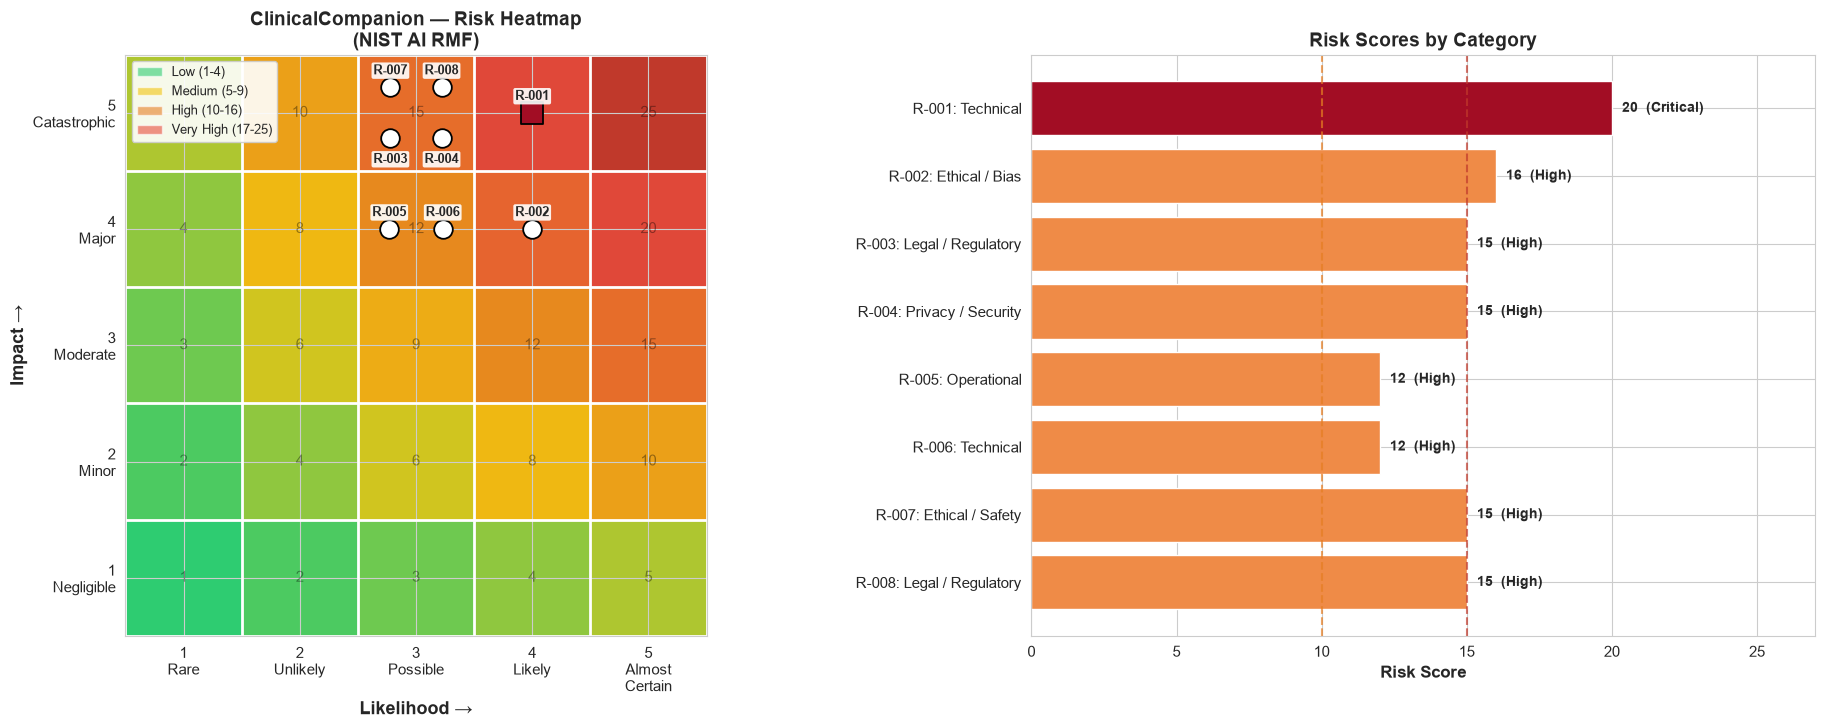

✅ Saved: results/risk_heatmap.png


In [11]:

# Step 4a: Create the risk heatmap visualization

from matplotlib.colors import LinearSegmentedColormap

# Load the original risk data
risk_df = pd.read_csv(DATA_DIR / "risk_register.csv")

# Create two panels side by side
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(20, 8),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

# ==========================================
# LEFT PANEL: 5x5 RISK HEATMAP
# ==========================================

# Calculate background risk scores
score_matrix = np.array([
    [(i + 1) * (j + 1) for j in range(5)]
    for i in range(5)
])

# Create green-to-red risk colors
cmap = LinearSegmentedColormap.from_list(
    "risk",
    ["#2ecc71", "#f1c40f", "#e67e22",
     "#e74c3c", "#c0392b"],
    N=256
)

# Display heatmap
ax1.imshow(
    score_matrix,
    origin="lower",
    cmap=cmap,
    vmin=1,
    vmax=25
)

# Draw white grid lines
for border in range(6):
    ax1.axhline(
        border - 0.5,
        color="white",
        linewidth=2
    )
    ax1.axvline(
        border - 0.5,
        color="white",
        linewidth=2
    )

# Plot each risk on the heatmap
# Small offsets make overlapping risks visible
for (likelihood, impact), group in risk_df.groupby(
    ["likelihood", "impact"], sort=False
):
    n = len(group)

    offsets = {
        1: [(0, 0)],
        2: [(-0.23, 0), (0.23, 0)],
        3: [(-0.22, -0.20), (0.22, -0.20),
            (0, 0.22)],
        4: [(-0.22, -0.22), (0.22, -0.22),
            (-0.22, 0.22), (0.22, 0.22)]
    }.get(n, [(0, 0)] * n)

    for (_, risk), (dx, dy) in zip(
        group.iterrows(), offsets
    ):
        x = likelihood - 1 + dx
        y = impact - 1 + dy

        is_critical = risk["priority"] == "Critical"

        ax1.scatter(
            x, y,
            marker="s" if is_critical else "o",
            s=240 if is_critical else 180,
            c="#a20d24" if is_critical else "#ffffff",
            edgecolors="black",
            linewidths=1.3,
            zorder=4
        )

        # Label each individual risk
        ax1.annotate(
            risk["risk_id"],
            (x, y),
            xytext=(0, 12 if dy >= 0 else -15),
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.15",
                fc="white",
                alpha=0.9,
                ec="none"
            ),
            zorder=5
        )

# Display risk score numbers inside cells
for impact in range(1, 6):
    for likelihood in range(1, 6):
        score = likelihood * impact

        ax1.text(
            likelihood - 1,
            impact - 1,
            str(score),
            ha="center",
            va="center",
            fontsize=11,
            alpha=0.38,
            color="black"
        )

# Axis formatting
ax1.set_xlabel(
    "Likelihood →",
    fontsize=13,
    fontweight="bold"
)

ax1.set_ylabel(
    "Impact →",
    fontsize=13,
    fontweight="bold"
)

ax1.set_title(
    "ClinicalCompanion — Risk Heatmap\n(NIST AI RMF)",
    fontsize=14,
    fontweight="bold"
)

ax1.set_xticks(range(5))
ax1.set_xticklabels([
    "1\nRare",
    "2\nUnlikely",
    "3\nPossible",
    "4\nLikely",
    "5\nAlmost\nCertain"
])

ax1.set_yticks(range(5))
ax1.set_yticklabels([
    "1\nNegligible",
    "2\nMinor",
    "3\nModerate",
    "4\nMajor",
    "5\nCatastrophic"
])

# Heatmap legend
ax1.legend(handles=[
    mpatches.Patch(
        fc="#2ecc71", alpha=0.6,
        label="Low (1-4)"
    ),
    mpatches.Patch(
        fc="#f1c40f", alpha=0.6,
        label="Medium (5-9)"
    ),
    mpatches.Patch(
        fc="#e67e22", alpha=0.6,
        label="High (10-16)"
    ),
    mpatches.Patch(
        fc="#e74c3c", alpha=0.6,
        label="Very High (17-25)"
    )
], loc="upper left", fontsize=9, framealpha=0.9)


# ==========================================
# RIGHT PANEL: HORIZONTAL RISK BAR CHART
# ==========================================

# Assign colors based on risk priority
colors = [
    "#a20d24" if priority == "Critical"
    else "#ef8b47"
    for priority in risk_df["priority"]
]

# Draw horizontal bars
bars = ax2.barh(
    range(len(risk_df)),
    risk_df["risk_score"],
    color=colors,
    edgecolor="white"
)

# Add risk score and priority labels
for i, risk in risk_df.iterrows():
    ax2.text(
        risk["risk_score"] + 0.35,
        i,
        f"{risk['risk_score']}  ({risk['priority']})",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Reference lines for risk scores 10 and 15
ax2.axvline(
    10,
    color="#e67e22",
    linestyle="--",
    alpha=0.7
)

ax2.axvline(
    15,
    color="#c0392b",
    linestyle="--",
    alpha=0.7
)

# Axis formatting
ax2.set_yticks(range(len(risk_df)))

ax2.set_yticklabels([
    f"{r['risk_id']}: {r['risk_category']}"
    for _, r in risk_df.iterrows()
])

ax2.set_xlabel(
    "Risk Score",
    fontsize=12,
    fontweight="bold"
)

ax2.set_title(
    "Risk Scores by Category",
    fontsize=14,
    fontweight="bold"
)

ax2.set_xlim(0, 27)
ax2.invert_yaxis()

# ==========================================
# SAVE FINAL VISUALIZATION
# ==========================================

plt.tight_layout(pad=3)

plt.savefig(
    RESULTS_DIR / "risk_heatmap.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("✅ Saved: results/risk_heatmap.png")


### 4b. Create the pre vs. post-mitigation comparison chart

🔧 **TODO:** Create a grouped bar chart comparing pre-mitigation and post-mitigation risk scores:
- Side-by-side bars (red = pre, green = post) for each risk
- Score labels on top of each bar
- Percentage reduction annotated above each pair
- Reference lines at scores 10 and 15
- Save as `results/risk_mitigation_comparison.png`

*Hint: Use `np.arange()` for bar positions and offset by bar width/2 for grouping*

RISK MITIGATION SUMMARY
----------------------------------------
Original Total Score: 120
Projected Residual Score: 63
Projected Reduction: 47.5%


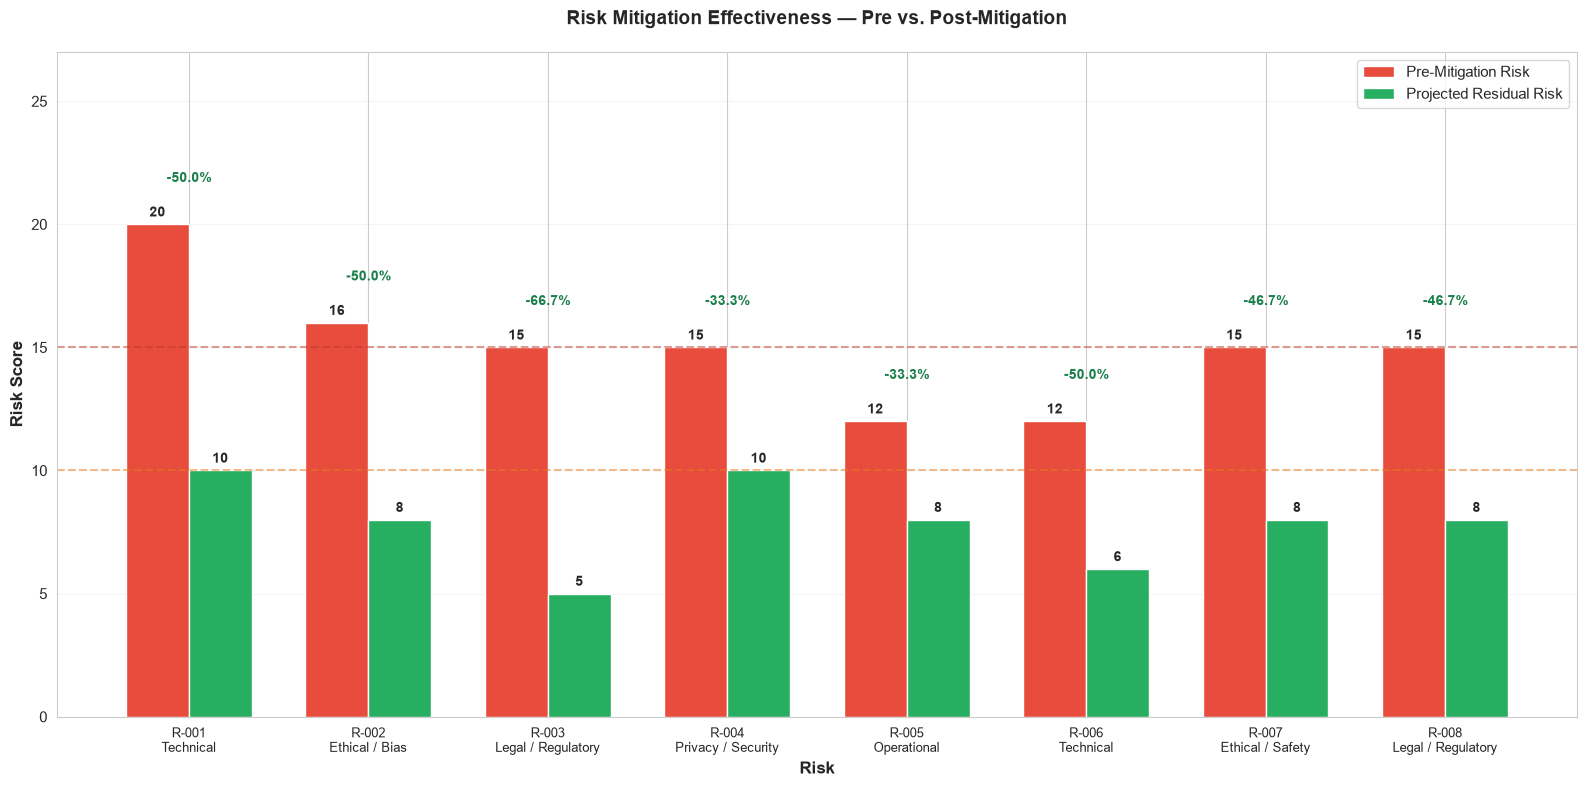

Saved: results/risk_mitigation_comparison.png


In [12]:

# Step 4b: Pre vs. post-mitigation comparison

# Load the risk register
risk_df = pd.read_csv(DATA_DIR / "risk_register.csv")

# Calculate projected risk reduction
risk_df["reduction_pct"] = (
    (risk_df["risk_score"] - risk_df["residual_score"])
    / risk_df["risk_score"] * 100
)

# Set chart positions and bar width
x = np.arange(len(risk_df))
w = 0.35

fig, ax = plt.subplots(figsize=(16, 8))

# Pre-mitigation scores (red)
bars_pre = ax.bar(
    x - w / 2,
    risk_df["risk_score"],
    width=w,
    color="#e74c3c",
    label="Pre-Mitigation Risk",
    edgecolor="white"
)

# Projected residual scores (green)
bars_post = ax.bar(
    x + w / 2,
    risk_df["residual_score"],
    width=w,
    color="#27ae60",
    label="Projected Residual Risk",
    edgecolor="white"
)

# Add numerical scores above every bar
for bars in [bars_pre, bars_post]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.2,
            f"{height:.0f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

# Add percentage reduction above each pair
for i, risk in risk_df.iterrows():

    reduction = risk["reduction_pct"]
    highest_score = max(
        risk["risk_score"],
        risk["residual_score"]
    )

    ax.text(
        x[i],
        highest_score + 1.6,
        f"-{reduction:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#1b7f4b"
    )

# Add axis labels and title
ax.set_xlabel(
    "Risk",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Risk Score",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Risk Mitigation Effectiveness — Pre vs. Post-Mitigation",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# Add risk IDs and categories
ax.set_xticks(x)

ax.set_xticklabels(
    [
        f"{r['risk_id']}\n{r['risk_category']}"
        for _, r in risk_df.iterrows()
    ],
    fontsize=9
)

# Add reference lines at risk scores 10 and 15
ax.axhline(
    y=10,
    color="#e67e22",
    linestyle="--",
    alpha=0.5
)

ax.axhline(
    y=15,
    color="#c0392b",
    linestyle="--",
    alpha=0.5
)

# Final chart formatting
ax.set_ylim(0, 27)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Calculate overall projected reduction
total_before = risk_df["risk_score"].sum()
total_after = risk_df["residual_score"].sum()

overall_reduction = (
    (total_before - total_after)
    / total_before * 100
)

print("RISK MITIGATION SUMMARY")
print("-" * 40)
print(f"Original Total Score: {total_before}")
print(f"Projected Residual Score: {total_after}")
print(f"Projected Reduction: {overall_reduction:.1f}%")

# Save the visualization
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "risk_mitigation_comparison.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved: results/risk_mitigation_comparison.png")



---
## Step 5: Vendor Evaluation Visualization

**Time estimate: ~30 minutes**

Load the vendor assessment data and create a governance scorecard. The vendor (FoundationHealth Inc.) has been evaluated across 27 criteria in 5 categories.

*Full evaluation narrative goes in `governance_workbook.xlsx` → Sheet "Vendor Evaluation"*

### 5a. Load and analyze vendor data

🔧 **TODO:** Load `vendor_assessment.csv` and `vendor_profile.json`, then:
1. Calculate the score percentage for each category (score / max_score × 100)
2. Calculate the overall vendor score
3. Print a summary showing each category's score and the overall rating

*Scoring guide: ≥80% = Low Risk, 60-79% = Medium Risk, <60% = High Risk*

In [13]:

# Step 5a: Load and analyze vendor assessment data

# Load the vendor evaluation dataset
vendor_df = pd.read_csv(DATA_DIR / "vendor_assessment.csv")

# Load the vendor company profile
with open(DATA_DIR / "vendor_profile.json") as f:
    vendor = json.load(f)

print("=" * 70)
print("THIRD-PARTY AI VENDOR GOVERNANCE ASSESSMENT")
print("=" * 70)

print(f"Vendor: {vendor['company']['name']}")
print(f"Criteria Evaluated: {len(vendor_df)}")

# =========================================
# PART 1: CALCULATE CATEGORY SCORES
# =========================================

category_scores = vendor_df.groupby(
    "category", sort=False
).agg(
    total_score=("score", "sum"),
    max_score=("max_score", "sum")
)

# Calculate percentage scores
category_scores["score_pct"] = (
    category_scores["total_score"]
    / category_scores["max_score"]
) * 100

# =========================================
# PART 2: ASSIGN RISK LEVELS
# =========================================

def risk_rating(percentage):
    if percentage >= 80:
        return "Low Risk"
    elif percentage >= 60:
        return "Medium Risk"
    else:
        return "High Risk"

category_scores["risk_level"] = (
    category_scores["score_pct"].apply(risk_rating)
)

print("\n" + "=" * 70)
print("CATEGORY EVALUATION RESULTS")
print("=" * 70)

for category, row in category_scores.iterrows():

    print(f"\nCategory: {category}")

    print(
        f"Score: {row['total_score']}"
        f"/{row['max_score']}"
    )

    print(
        f"Percentage: {row['score_pct']:.1f}%"
    )

    print(
        f"Risk Rating: {row['risk_level']}"
    )

# =========================================
# PART 3: OVERALL VENDOR ASSESSMENT
# =========================================

total_score = vendor_df["score"].sum()
max_total = vendor_df["max_score"].sum()

overall_pct = (
    total_score / max_total
) * 100

overall_risk = risk_rating(overall_pct)

print("\n" + "=" * 70)
print("OVERALL VENDOR ASSESSMENT")
print("=" * 70)

print(f"Total Score: {total_score}/{max_total}")
print(f"Overall Score: {overall_pct:.1f}%")
print(f"Overall Risk Level: {overall_risk}")

# Identify categories requiring additional review
print("\nCATEGORIES REQUIRING IMPROVEMENT:")

for category, row in category_scores.iterrows():

    if row["risk_level"] != "Low Risk":
        print(
            f"- {category}: "
            f"{row['score_pct']:.1f}% "
            f"({row['risk_level']})"
        )

print("\nAssessment based on the supplied vendor evidence.")
print("Final approval requires verification and remediation.")



THIRD-PARTY AI VENDOR GOVERNANCE ASSESSMENT
Vendor: FoundationHealth Inc.
Criteria Evaluated: 27

CATEGORY EVALUATION RESULTS

Category: Model Transparency & Documentation
Score: 15/25
Percentage: 60.0%
Risk Rating: Medium Risk

Category: Data Privacy & Security
Score: 25/30
Percentage: 83.3%
Risk Rating: Low Risk

Category: Model Governance & Lifecycle
Score: 15/25
Percentage: 60.0%
Risk Rating: Medium Risk

Category: Contractual & Business Continuity
Score: 18/30
Percentage: 60.0%
Risk Rating: Medium Risk

Category: Regulatory & Ethical Alignment
Score: 15/25
Percentage: 60.0%
Risk Rating: Medium Risk

OVERALL VENDOR ASSESSMENT
Total Score: 88/135
Overall Score: 65.2%
Overall Risk Level: Medium Risk

CATEGORIES REQUIRING IMPROVEMENT:
- Model Transparency & Documentation: 60.0% (Medium Risk)
- Model Governance & Lifecycle: 60.0% (Medium Risk)
- Contractual & Business Continuity: 60.0% (Medium Risk)
- Regulatory & Ethical Alignment: 60.0% (Medium Risk)

Assessment based on the supplied

### 5b. Create vendor scorecard visualization

🔧 **TODO:** Create a figure with two subplots:

**Left — Horizontal bar chart:**
- One bar per vendor category showing score percentage
- Color-coded: green (≥80%), yellow (60-79%), red (<60%)
- Score labels showing "XX% (score/max)" on each bar
- Reference lines at 60% and 80%

**Right — Radar/spider chart:**
- Categories around the perimeter
- Score percentages as the radar values
- Reference circles at 60% and 80%

Save as `results/vendor_evaluation_chart.png`.

*Hint: For the radar chart, use `fig.add_subplot(122, polar=True)` and compute angles with `np.linspace(0, 2*np.pi, n, endpoint=False)`*

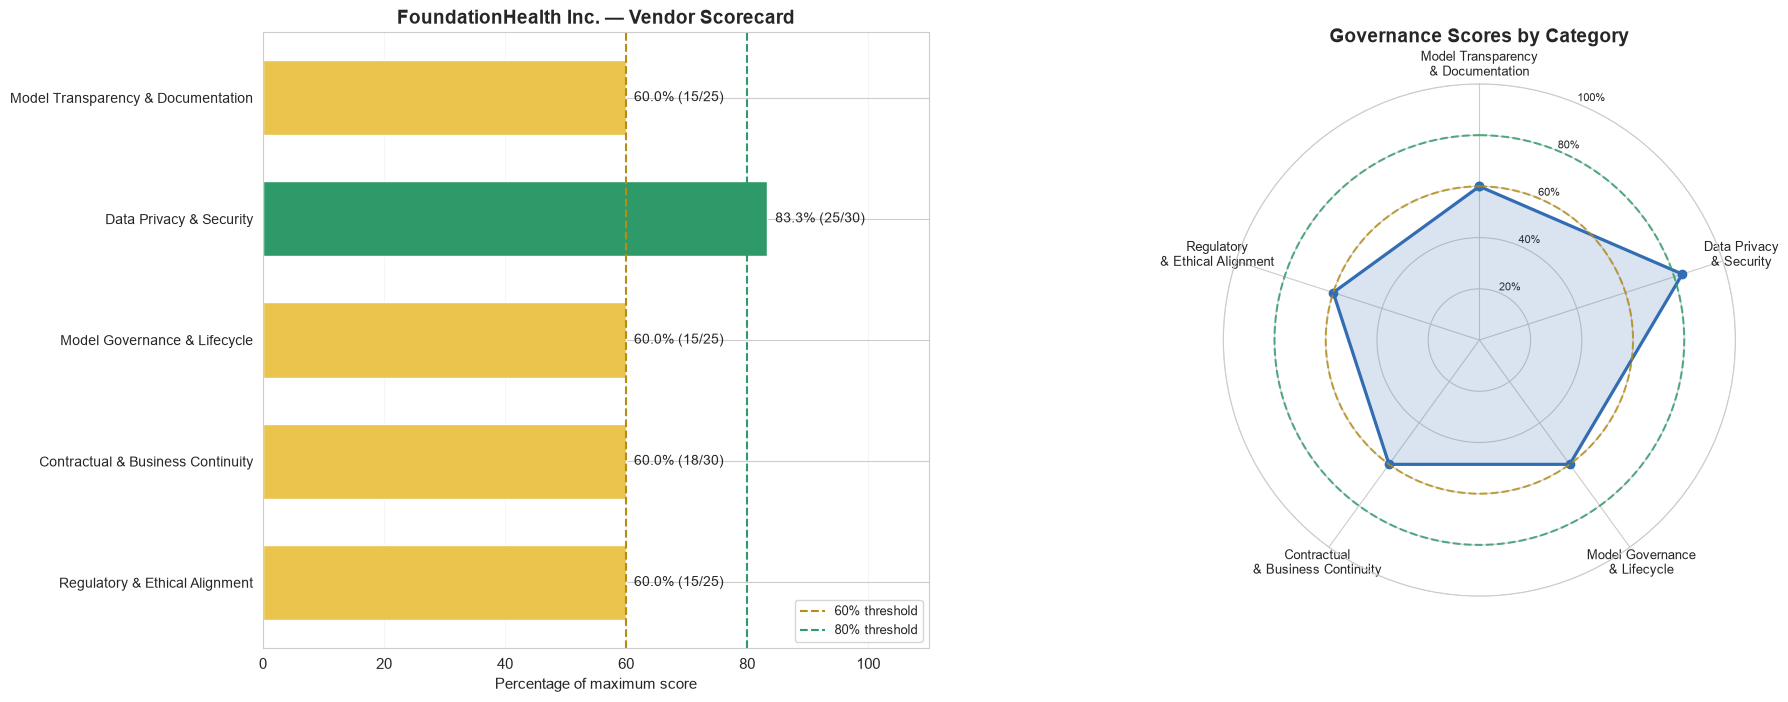

Saved: results/vendor_evaluation_chart.png


In [14]:

# Step 5b: Vendor Governance Scorecard

# Use the category scores calculated in Step 5a
categories = category_scores.index.tolist()
percentages = category_scores["score_pct"].to_numpy()
earned = category_scores["total_score"].to_numpy()
possible = category_scores["max_score"].to_numpy()

# Assign colors using Udacity's scoring thresholds
bar_colors = [
    "#2e9a69" if score >= 80
    else "#ebc44d" if score >= 60
    else "#d65a53"
    for score in percentages
]

# Create the two-panel figure
fig = plt.figure(figsize=(19, 8))
gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1.3, 1],
    wspace=0.5
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1], projection="polar")

# ======================================
# LEFT PANEL: HORIZONTAL BAR CHART
# ======================================

positions = np.arange(len(categories))

ax1.barh(
    positions,
    percentages,
    color=bar_colors,
    height=0.62
)

ax1.set_yticks(positions)
ax1.set_yticklabels(categories, fontsize=10)
ax1.invert_yaxis()
ax1.set_xlim(0, 110)

# Display percentages and raw scores
for pos, pct, score, maximum in zip(
    positions, percentages, earned, possible
):
    ax1.text(
        pct + 1.3,
        pos,
        f"{pct:.1f}% ({score}/{maximum})",
        va="center",
        fontsize=10
    )

# Add risk-rating thresholds
ax1.axvline(
    60,
    color="#b68c11",
    linestyle="--",
    linewidth=1.5,
    label="60% threshold"
)

ax1.axvline(
    80,
    color="#2e9a69",
    linestyle="--",
    linewidth=1.5,
    label="80% threshold"
)

ax1.set_xlabel("Percentage of maximum score")
ax1.set_title(
    "FoundationHealth Inc. — Vendor Scorecard",
    fontsize=14,
    fontweight="bold"
)

ax1.grid(axis="x", alpha=0.18)
ax1.set_axisbelow(True)
ax1.legend(loc="lower right", fontsize=9)

# ======================================
# RIGHT PANEL: RADAR / SPIDER CHART
# ======================================

# Calculate positions around the circle
n = len(categories)

angles = np.linspace(
    0, 2 * np.pi, n, endpoint=False
)

# Close the polygon by repeating first values
closed_angles = np.r_[angles, angles[0]]
closed_scores = np.r_[
    percentages, percentages[0]
]

# Plot the vendor's category scores
ax2.plot(
    closed_angles,
    closed_scores,
    color="#326db3",
    linewidth=2.3,
    marker="o"
)

ax2.fill(
    closed_angles,
    closed_scores,
    color="#326db3",
    alpha=0.18
)

# Create reference circles at 60% and 80%
reference_theta = np.linspace(
    0, 2 * np.pi, 361
)

ax2.plot(
    reference_theta,
    np.full_like(reference_theta, 60),
    linestyle="--",
    color="#b68c11",
    alpha=0.8
)

ax2.plot(
    reference_theta,
    np.full_like(reference_theta, 80),
    linestyle="--",
    color="#2e9a69",
    alpha=0.8
)

# Format the radar chart
ax2.set_theta_offset(np.pi / 2)
ax2.set_theta_direction(-1)

ax2.set_xticks(angles)
ax2.set_xticklabels(
    [
        name.replace(" & ", "\n& ")
        for name in categories
    ],
    fontsize=9
)

ax2.set_ylim(0, 100)
ax2.set_yticks([20, 40, 60, 80, 100])
ax2.set_yticklabels(
    ["20%", "40%", "60%", "80%", "100%"],
    fontsize=8
)

ax2.set_title(
    "Governance Scores by Category",
    fontsize=14,
    fontweight="bold",
    pad=30
)

# ======================================
# SAVE THE VISUALIZATION
# ======================================

plt.savefig(
    RESULTS_DIR / "vendor_evaluation_chart.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved: results/vendor_evaluation_chart.png")


---
## Step 6: Model Card — Performance Analysis

**Time estimate: ~30 minutes**

Visualize disaggregated performance metrics for the Model Card fairness analysis. The Model Card framework (Mitchell et al., 2019) requires showing how the model performs across different subgroups, not just overall.

*Full Model Card content goes in `governance_workbook.xlsx` → Sheet "Model Card"*

### 6a. Analyze disaggregated performance

🔧 **TODO:** Load `performance_metrics.csv` and:
1. Filter for "Top-3 Diagnostic Accuracy" metrics across all subgroups
2. Identify which subgroups fall BELOW the 90% target
3. Print a summary of failing subgroups with their accuracy values

*Think about: What are the governance implications of these performance gaps? How do they relate to EU AI Act Article 10 (dataset representativeness)?*

In [15]:

# Step 6a: Analyze disaggregated model performance

# Load the original performance data
perf_df = pd.read_csv(
    DATA_DIR / "performance_metrics.csv"
)

print("=" * 70)
print("CLINICALCOMPANION — MODEL CARD PERFORMANCE")
print("=" * 70)

# PART 1: Filter for Top-3 Diagnostic Accuracy
accuracy_df = perf_df[
    perf_df["metric_name"] == "Top-3 Diagnostic Accuracy"
].copy()

print("\nTOP-3 DIAGNOSTIC ACCURACY BY SUBGROUP:")
print("-" * 70)

print(
    accuracy_df[
        ["subgroup", "value", "target", "sample_size"]
    ].to_string(index=False)
)

# PART 2: Identify subgroups below the 90% target
target = 90.0

below_target = accuracy_df[
    accuracy_df["value"] < target
].copy()

# Calculate the performance shortfall
below_target["gap_pp"] = (
    target - below_target["value"]
)

print("\n" + "=" * 70)
print("SUBGROUPS BELOW THE 90% TARGET")
print("=" * 70)

for _, row in below_target.iterrows():
    print(
        f"{row['subgroup']}: "
        f"{row['value']:.1f}% accuracy | "
        f"{row['gap_pp']:.1f} pp below target | "
        f"Sample size: {row['sample_size']:,}"
    )

# PART 3: Summary statistics
overall_accuracy = accuracy_df.loc[
    accuracy_df["subgroup"] == "Overall",
    "value"
].iloc[0]

print("\n" + "=" * 70)
print("PERFORMANCE SUMMARY")
print("=" * 70)

print(f"Overall Top-3 Accuracy: {overall_accuracy:.1f}%")
print(f"Target Accuracy: {target:.1f}%")
print(f"Subgroups Evaluated: {len(accuracy_df) - 1}")
print(f"Subgroups Below Target: {len(below_target)}")

# Identify the lowest-performing subgroup
lowest = accuracy_df.loc[
    accuracy_df["value"].idxmin()
]

print(
    f"Lowest Performing Subgroup: "
    f"{lowest['subgroup']} ({lowest['value']:.1f}%)"
)

# PART 4: Governance implications
print("\n" + "=" * 70)
print("AI GOVERNANCE IMPLICATIONS")
print("=" * 70)

print("1. Investigate underperforming patient subgroups.")
print("2. Review training data coverage and representativeness.")
print("3. Evaluate clinical safety impacts of performance gaps.")
print("4. Establish subgroup-specific monitoring and testing.")
print("5. Validate mitigation effectiveness before deployment.")



CLINICALCOMPANION — MODEL CARD PERFORMANCE

TOP-3 DIAGNOSTIC ACCURACY BY SUBGROUP:
----------------------------------------------------------------------
            subgroup  value target  sample_size
             Overall   91.7   90.0        45000
                Male   92.1   90.0        23400
              Female   91.3   90.0        21600
           Age 18-40   93.5   90.0        11200
           Age 41-64   92.0   90.0        19800
             Age 65+   88.9   90.0        14000
      Cardiovascular   94.1   90.0         8500
        Neurological   90.3   90.0         6200
       Rare Diseases   71.2   90.0         1035
   Non-English Notes   84.3   90.0         5400
Multi-morbidity (4+)   74.0   90.0         7650

SUBGROUPS BELOW THE 90% TARGET
Age 65+: 88.9% accuracy | 1.1 pp below target | Sample size: 14,000
Rare Diseases: 71.2% accuracy | 18.8 pp below target | Sample size: 1,035
Non-English Notes: 84.3% accuracy | 5.7 pp below target | Sample size: 5,400
Multi-morbidity (4+

### 6b. Create disaggregated performance bar chart

🔧 **TODO:** Create a bar chart showing Top-3 Diagnostic Accuracy by subgroup:
- One bar per subgroup
- Color-coded: green (≥90%), yellow (85-89%), orange (80-84%), red (<80%)
- The "Overall" bar highlighted with a distinct border
- Reference lines at 90%, 85%, and 80% thresholds
- Value labels on top of each bar
- Rotated x-axis labels for readability

Save as `results/model_card_performance.png`.

*Print a list of subgroups below the 85% threshold — these need mitigation.*

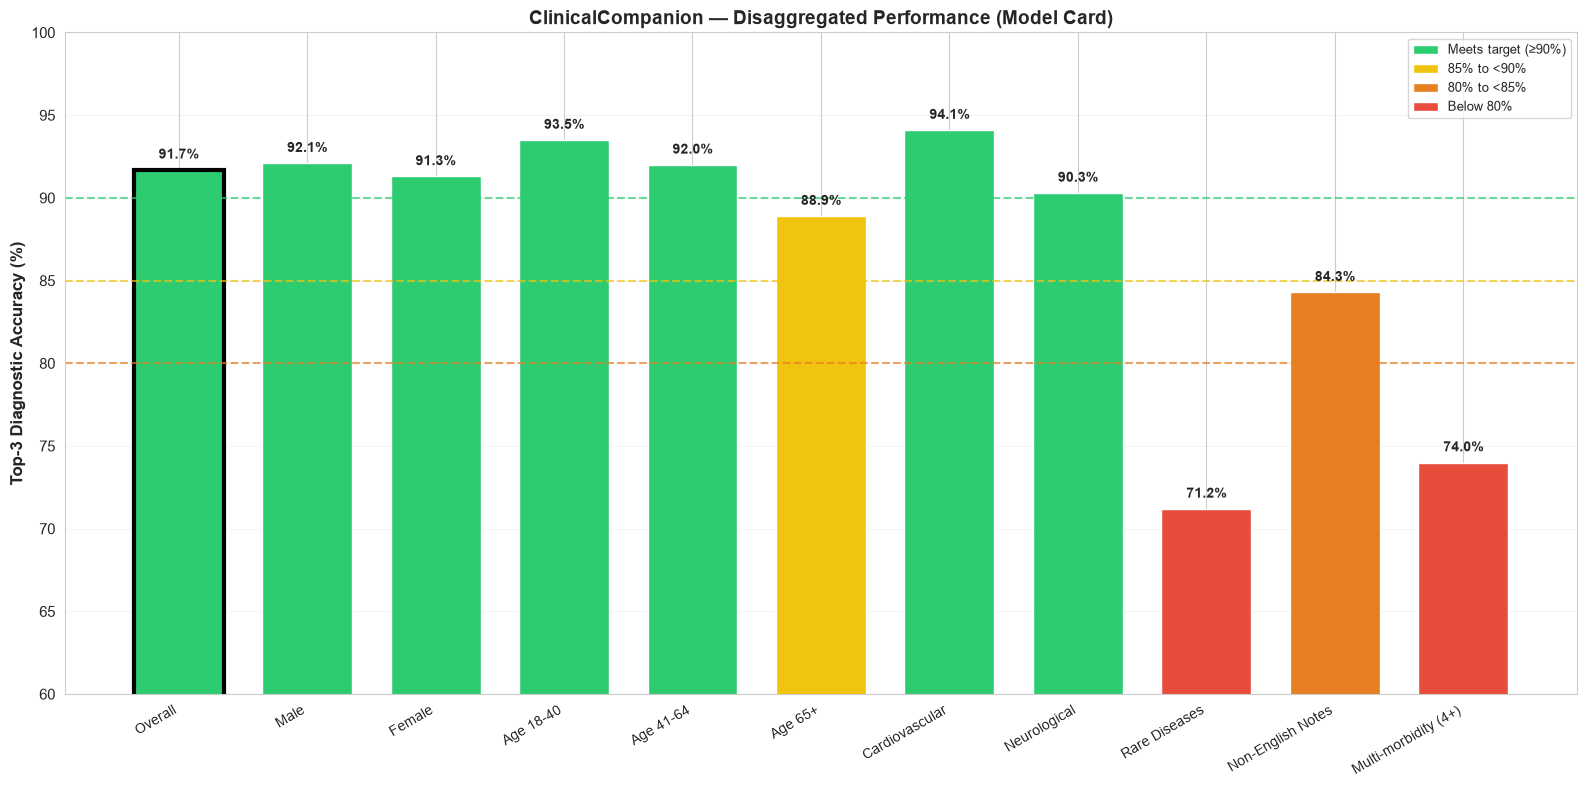


SUBGROUPS BELOW 85% THRESHOLD:
--------------------------------------------------
Rare Diseases: 71.2% (Sample size: 1,035)
Non-English Notes: 84.3% (Sample size: 5,400)
Multi-morbidity (4+): 74.0% (Sample size: 7,650)

Total below 85%: 3
Saved: results/model_card_performance.png


In [16]:

# Step 6b: Create disaggregated performance visualization

from matplotlib.patches import Patch

# Use Top-3 Diagnostic Accuracy data from Step 6a
accuracy_df = perf_df[
    perf_df["metric_name"] == "Top-3 Diagnostic Accuracy"
].copy()

fig, ax = plt.subplots(figsize=(16, 8))

# ==========================================
# PART 1: ASSIGN PERFORMANCE COLORS
# ==========================================

def get_performance_color(accuracy):
    if accuracy >= 90:
        return "#2ecc71"   # Green
    elif accuracy >= 85:
        return "#f1c40f"   # Yellow
    elif accuracy >= 80:
        return "#e67e22"   # Orange
    else:
        return "#e74c3c"   # Red

colors = [
    get_performance_color(value)
    for value in accuracy_df["value"]
]

# ==========================================
# PART 2: CREATE BAR CHART
# ==========================================

positions = np.arange(len(accuracy_df))

bars = ax.bar(
    positions,
    accuracy_df["value"],
    color=colors,
    width=0.7,
    edgecolor="white",
    linewidth=1
)

# ==========================================
# PART 3: HIGHLIGHT OVERALL PERFORMANCE
# ==========================================

for i, bar in enumerate(bars):
    subgroup = accuracy_df.iloc[i]["subgroup"]

    if subgroup == "Overall":
        bar.set_edgecolor("black")
        bar.set_linewidth(3)

# ==========================================
# PART 4: ADD ACCURACY LABELS
# ==========================================

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# ==========================================
# PART 5: ADD REFERENCE THRESHOLDS
# ==========================================

ax.axhline(
    y=90,
    color="#2ecc71",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

ax.axhline(
    y=85,
    color="#f1c40f",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

ax.axhline(
    y=80,
    color="#e67e22",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

# ==========================================
# PART 6: FORMAT CHART
# ==========================================

ax.set_xticks(positions)

ax.set_xticklabels(
    accuracy_df["subgroup"],
    fontsize=10,
    rotation=30,
    ha="right"
)

ax.set_ylabel(
    "Top-3 Diagnostic Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "ClinicalCompanion — Disaggregated Performance (Model Card)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylim(60, 100)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Add legend
legend_items = [
    Patch(facecolor="#2ecc71", label="Meets target (≥90%)"),
    Patch(facecolor="#f1c40f", label="85% to <90%"),
    Patch(facecolor="#e67e22", label="80% to <85%"),
    Patch(facecolor="#e74c3c", label="Below 80%")
]

ax.legend(
    handles=legend_items,
    loc="upper right",
    fontsize=9
)

# ==========================================
# PART 7: SAVE VISUALIZATION
# ==========================================

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "model_card_performance.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ==========================================
# PART 8: PRINT UNDERPERFORMING SUBGROUPS
# ==========================================

below_85 = accuracy_df[
    accuracy_df["value"] < 85
].copy()

print("\nSUBGROUPS BELOW 85% THRESHOLD:")
print("-" * 50)

for _, row in below_85.iterrows():
    print(
        f"{row['subgroup']}: "
        f"{row['value']:.1f}% "
        f"(Sample size: {row['sample_size']:,})"
    )

print(f"\nTotal below 85%: {len(below_85)}")
print("Saved: results/model_card_performance.png")


---
## Step 7: Monitoring & Incident Response Dashboard

**Time estimate: ~30 minutes**

Create a multi-panel monitoring dashboard that visualizes KPIs, incident taxonomy, and response framework.

*Full monitoring plan goes in `governance_workbook.xlsx` → Sheet "Monitoring & Incidents"*

### 7a. Load monitoring data

🔧 **TODO:** Load the three monitoring data files:
- `monitoring_kpis.csv` — 16 KPI definitions
- `incident_types.csv` — 10 AI-specific incident types
- `severity_levels.csv` — S1-S4 severity levels

Print a brief summary of each (number of KPIs by dimension, number of incident types, severity levels).

In [17]:

# Step 7a: Load and summarize monitoring data

# Load the three provided datasets
kpi_df = pd.read_csv(
    DATA_DIR / "monitoring_kpis.csv"
)

incident_df = pd.read_csv(
    DATA_DIR / "incident_types.csv"
)

severity_df = pd.read_csv(
    DATA_DIR / "severity_levels.csv"
)

# ======================================
# PART 1: MONITORING KPI SUMMARY
# ======================================

print("=" * 70)
print("CLINICALCOMPANION — MONITORING FRAMEWORK")
print("=" * 70)

print(f"\nTotal Monitoring KPIs: {len(kpi_df)}")

print("\nKPI COVERAGE BY DIMENSION:")
print("-" * 50)

dimension_counts = (
    kpi_df.groupby("dimension")
    .size()
    .sort_values(ascending=False)
)

for dimension, count in dimension_counts.items():
    print(f"{dimension}: {count} KPIs")

# ======================================
# PART 2: INCIDENT TAXONOMY
# ======================================

print("\n" + "=" * 70)
print("AI INCIDENT CATEGORIES")
print("=" * 70)

print(f"Total Incident Types: {len(incident_df)}")

for _, row in incident_df.iterrows():
    print(
        f"{row['incident_id']} | "
        f"{row['incident_type']} | "
        f"Severity Range: {row['severity_range']}"
    )

# ======================================
# PART 3: INCIDENT SEVERITY LEVELS
# ======================================

print("\n" + "=" * 70)
print("INCIDENT SEVERITY & RESPONSE SLAs")
print("=" * 70)

for _, row in severity_df.iterrows():

    print(f"\nSeverity: {row['severity']}")
    print(f"Label: {row['label']}")
    print(f"Response Target: {row['response_time']}")
    print(f"Response Hours: {row['response_hours']}")
    print(f"Incident Commander: {row['incident_commander']}")

# ======================================
# PART 4: GOVERNANCE SUMMARY
# ======================================

print("\n" + "=" * 70)
print("MONITORING GOVERNANCE SUMMARY")
print("=" * 70)

print(f"KPIs Defined: {len(kpi_df)}")
print(f"Monitoring Dimensions: {kpi_df['dimension'].nunique()}")
print(f"Incident Types Defined: {len(incident_df)}")
print(f"Severity Levels Defined: {len(severity_df)}")

print("\nMonitoring controls must be validated")
print("before production deployment.")



CLINICALCOMPANION — MONITORING FRAMEWORK

Total Monitoring KPIs: 16

KPI COVERAGE BY DIMENSION:
--------------------------------------------------
Clinical Performance: 5 KPIs
Fairness & Bias: 4 KPIs
Operational: 4 KPIs
Data Quality: 3 KPIs

AI INCIDENT CATEGORIES
Total Incident Types: 10
INC-01 | Clinical Hallucination | Severity Range: S2-S1
INC-02 | Harmful Suggestion | Severity Range: S1
INC-03 | Bias-Related Harm | Severity Range: S2-S1
INC-04 | Privacy Breach | Severity Range: S1
INC-05 | Performance Degradation | Severity Range: S3-S2
INC-06 | Adversarial Manipulation | Severity Range: S2-S1
INC-07 | Vendor Service Disruption | Severity Range: S3-S2
INC-08 | Data Pipeline Failure | Severity Range: S1
INC-09 | Unauthorized Access | Severity Range: S2-S1
INC-10 | Regulatory Non-Compliance | Severity Range: S3-S2

INCIDENT SEVERITY & RESPONSE SLAs

Severity: S1
Label: Critical
Response Target: Immediate (30 min)
Response Hours: 0.5
Incident Commander: Chief Medical Officer

Severit

### 7b. Create monitoring dashboard (4 panels)

🔧 **TODO:** Create a 2×2 dashboard with these panels:

**Panel 1 (top-left): KPI Status vs. Targets**
- Select 6 key KPIs and show current values as bars
- Overlay target values as dashed horizontal lines
- Color: green if meeting target, red if below

**Panel 2 (top-right): Incident Distribution**
- Pie chart showing distribution across severity levels (S1-S4)

**Panel 3 (bottom-left): Response Time SLAs**
- Horizontal bar chart showing response time for each severity level
- Use log scale for x-axis (ranges from 0.5h to 168h)
- Color-coded by severity (red→green)

**Panel 4 (bottom-right): Monitoring Coverage**
- Bar chart showing number of KPIs per dimension
- Shows which areas have more/less monitoring coverage

Save as `results/monitoring_dashboard.png`.

*Hint: Use `plt.subplots(2, 2, figsize=(16, 12))` for the 4-panel layout*

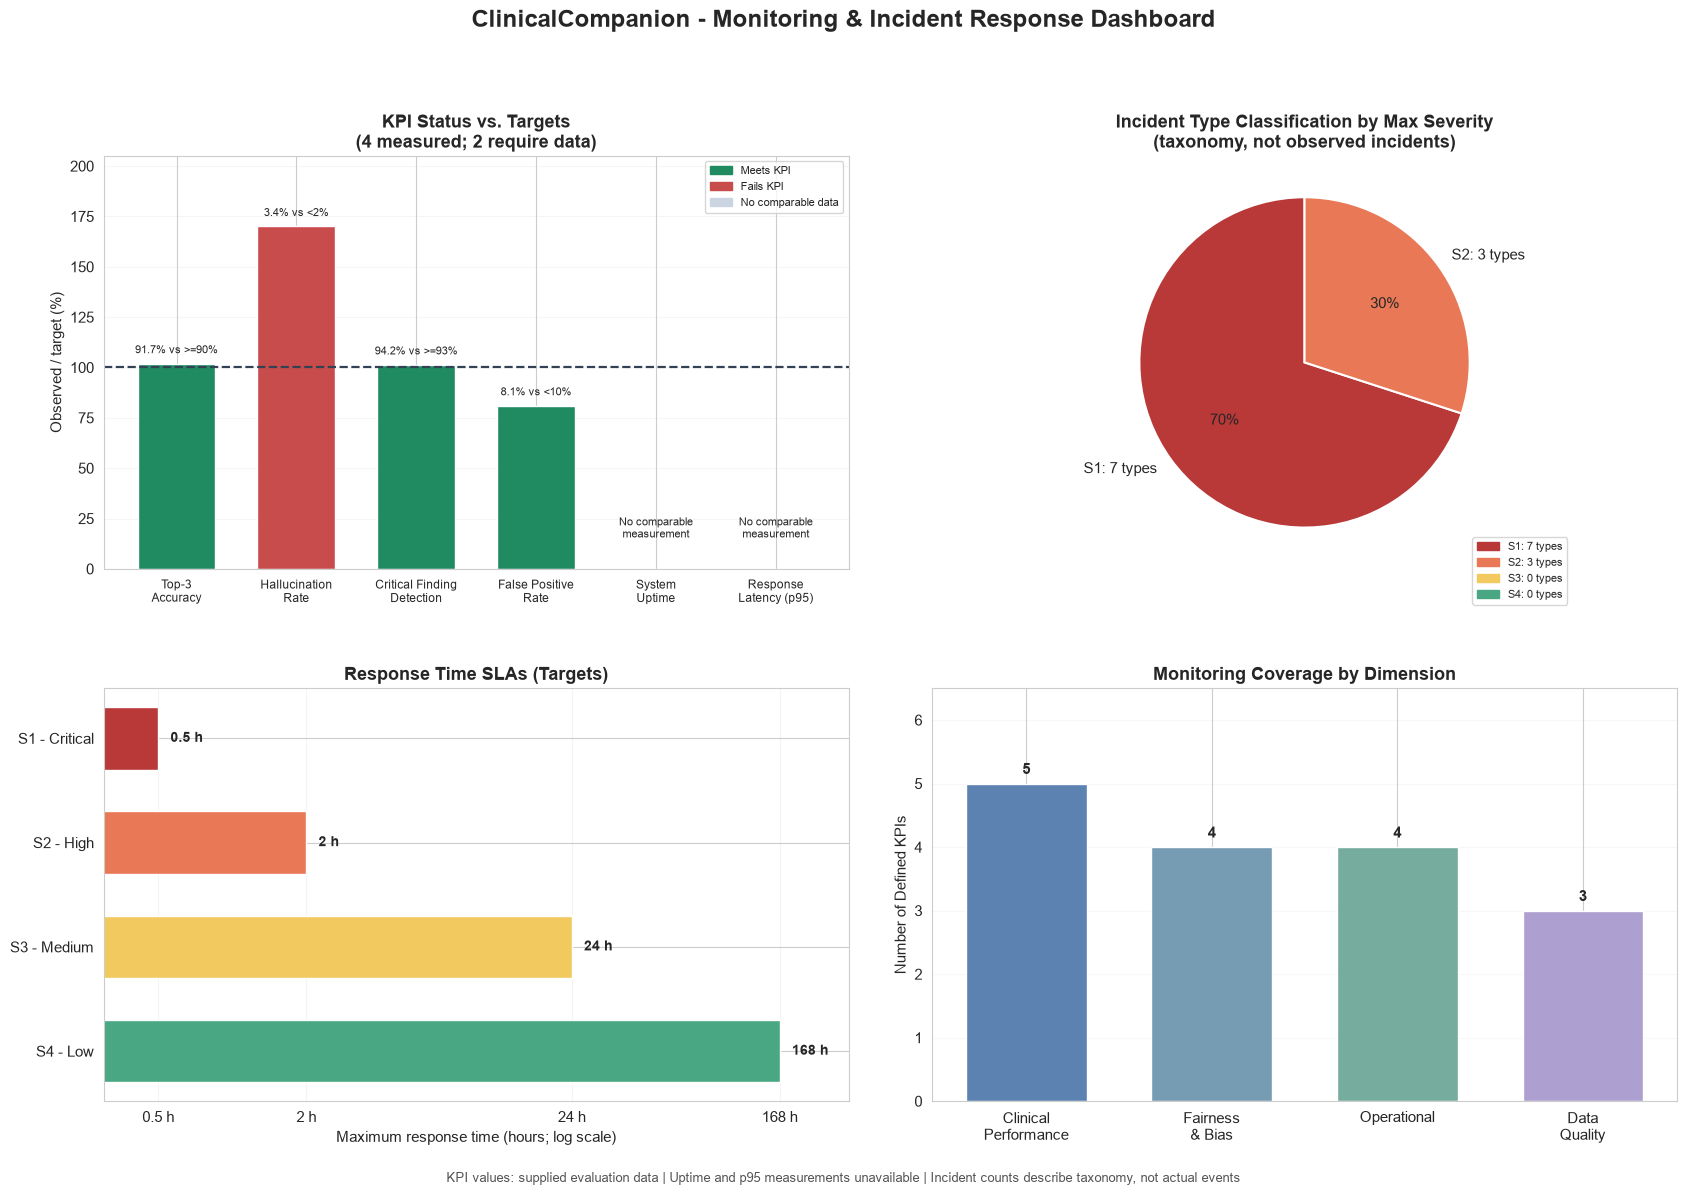

Saved: results/monitoring_dashboard.png

INCIDENT TAXONOMY BY HIGHEST SEVERITY:
max_severity
S1    7
S2    3
S3    0
S4    0

KPI COVERAGE:
dimension
Clinical Performance    5
Fairness & Bias         4
Operational             4
Data Quality            3


In [18]:

# Step 7b: Create 4-panel monitoring dashboard

import re
import matplotlib.patches as mpatches

# Load original Udacity data
kpi_df = pd.read_csv(DATA_DIR / "monitoring_kpis.csv")
incident_df = pd.read_csv(DATA_DIR / "incident_types.csv")
severity_df = pd.read_csv(DATA_DIR / "severity_levels.csv")
perf_df = pd.read_csv(DATA_DIR / "performance_metrics.csv")

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

# ==========================================
# PANEL 1: KPI STATUS VS TARGETS
# ==========================================

ax = axes[0, 0]

# Display name, monitoring KPI name, performance metric
# None means no directly comparable measurement exists.
kpi_specs = [
    ("Top-3\nAccuracy",
     "Top-3 Diagnostic Accuracy",
     "Top-3 Diagnostic Accuracy"),

    ("Hallucination\nRate",
     "Hallucination Rate",
     "Hallucination Rate"),

    ("Critical Finding\nDetection",
     "Critical Finding Detection",
     "Critical Finding Detection"),

    ("False Positive\nRate",
     "False Positive Rate (Critical)",
     "False Positive Rate (Critical)"),

    ("System\nUptime",
     "System Uptime",
     None),

    ("Response\nLatency (p95)",
     "Average Response Latency",
     None)
]

# The source has average latency, not p95 latency.
# Do not substitute one statistic for the other.

observed = perf_df[
    perf_df["subgroup"] == "Overall"
].set_index("metric_name")["value"]

thresholds = kpi_df.set_index(
    "metric_name"
)["threshold"]

bar_values = []
bar_colors = []
bar_labels = []

for display_name, kpi_name, perf_name in kpi_specs:

    threshold_text = str(thresholds.loc[kpi_name])

    # Extract comparison operator and numeric target
    match = re.search(
        r"(>=|<=|>|<)\s*(\d+(?:\.\d+)?)",
        threshold_text
    )

    if not match:
        raise ValueError(
            f"Cannot parse KPI target: {threshold_text}"
        )

    operator = match.group(1)
    target = float(match.group(2))

    # Mark KPIs without comparable observed data
    if perf_name is None:
        bar_values.append(0)
        bar_colors.append("#cbd5e1")
        bar_labels.append("No comparable\nmeasurement")
        continue

    value = float(observed.loc[perf_name])

    # Determine whether the actual value meets target
    if operator == ">=":
        meets = value >= target
    elif operator == ">":
        meets = value > target
    elif operator == "<=":
        meets = value <= target
    else:
        meets = value < target

    # Normalize different KPIs relative to their targets
    normalized = (value / target) * 100

    bar_values.append(normalized)

    bar_colors.append(
        "#208b61" if meets else "#c94c4c"
    )

    bar_labels.append(
        f"{value:g}% vs {operator}{target:g}%"
    )

positions = np.arange(len(kpi_specs))

ax.bar(
    positions,
    bar_values,
    color=bar_colors,
    width=0.65,
    edgecolor="white"
)

# All targets are represented by the 100% reference line
ax.axhline(
    100,
    color="#334155",
    linestyle="--",
    linewidth=1.6
)

for pos, value, label in zip(
    positions, bar_values, bar_labels
):
    ax.text(
        pos,
        max(value, 10) + 4,
        label,
        ha="center",
        va="bottom",
        fontsize=8
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    [item[0] for item in kpi_specs],
    fontsize=8.5
)

ax.set_ylim(0, 205)
ax.set_ylabel("Observed / target (%)")

ax.set_title(
    "KPI Status vs. Targets\n"
    "(4 measured; 2 require data)",
    fontweight="bold"
)

ax.legend(
    handles=[
        mpatches.Patch(
            color="#208b61",
            label="Meets KPI"
        ),
        mpatches.Patch(
            color="#c94c4c",
            label="Fails KPI"
        ),
        mpatches.Patch(
            color="#cbd5e1",
            label="No comparable data"
        )
    ],
    fontsize=8,
    loc="upper right"
)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)

# ==========================================
# PANEL 2: INCIDENT CLASSIFICATION
# ==========================================

ax = axes[0, 1]

# Select the highest severity allowed for each
# incident type (S1 is more severe than S2, etc.).
def highest_severity(value):
    levels = re.findall(r"S[1-4]", str(value))

    return min(
        levels,
        key=lambda level: int(level[1:])
    )

incident_df["max_severity"] = (
    incident_df["severity_range"].apply(
        highest_severity
    )
)

severity_order = ["S1", "S2", "S3", "S4"]

severity_counts = (
    incident_df["max_severity"]
    .value_counts()
    .reindex(severity_order, fill_value=0)
)

severity_colors = {
    "S1": "#b93838",
    "S2": "#e97857",
    "S3": "#f1c95e",
    "S4": "#49a783"
}

nonzero_counts = severity_counts[
    severity_counts > 0
]

ax.pie(
    nonzero_counts.values,
    labels=[
        f"{level}: {count} types"
        for level, count in nonzero_counts.items()
    ],
    colors=[
        severity_colors[level]
        for level in nonzero_counts.index
    ],
    autopct="%1.0f%%",
    startangle=90,
    wedgeprops={
        "linewidth": 1.5,
        "edgecolor": "white"
    }
)

ax.legend(
    handles=[
        mpatches.Patch(
            color=severity_colors[level],
            label=f"{level}: {severity_counts[level]} types"
        )
        for level in severity_order
    ],
    loc="lower right",
    bbox_to_anchor=(1.15, -0.1),
    fontsize=8
)

ax.set_title(
    "Incident Type Classification by Max Severity\n"
    "(taxonomy, not observed incidents)",
    fontweight="bold"
)

# ==========================================
# PANEL 3: RESPONSE TIME SLAs
# ==========================================

ax = axes[1, 0]

severity_names = [
    f"{row['severity']} - {row['label']}"
    for _, row in severity_df.iterrows()
]

response_hours = (
    severity_df["response_hours"]
    .astype(float)
    .to_numpy()
)

response_colors = [
    severity_colors[level]
    for level in severity_df["severity"]
]

ax.barh(
    severity_names,
    response_hours,
    color=response_colors,
    height=0.6
)

# Use logarithmic scale because time spans
# range from 0.5 hours to 168 hours.
ax.set_xscale("log")
ax.set_xlim(0.3, 320)
ax.invert_yaxis()

ax.set_xticks([0.5, 2, 24, 168])
ax.set_xticklabels([
    "0.5 h", "2 h", "24 h", "168 h"
])

for i, hours in enumerate(response_hours):
    ax.text(
        hours * 1.12,
        i,
        f"{hours:g} h",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Response Time SLAs (Targets)",
    fontweight="bold"
)

ax.set_xlabel(
    "Maximum response time (hours; log scale)"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# ==========================================
# PANEL 4: MONITORING COVERAGE
# ==========================================

ax = axes[1, 1]

dimension_order = [
    "Clinical Performance",
    "Fairness & Bias",
    "Operational",
    "Data Quality"
]

dimension_counts = (
    kpi_df.groupby("dimension")
    .size()
    .reindex(dimension_order, fill_value=0)
)

bars = ax.bar(
    range(len(dimension_counts)),
    dimension_counts.values,
    color=[
        "#5c82b2",
        "#769cb3",
        "#76ac9d",
        "#ad9fd0"
    ],
    width=0.65
)

ax.set_xticks(range(len(dimension_counts)))

ax.set_xticklabels([
    "Clinical\nPerformance",
    "Fairness\n& Bias",
    "Operational",
    "Data\nQuality"
])

for bar, count in zip(
    bars, dimension_counts.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 0.15,
        str(count),
        ha="center",
        fontweight="bold"
    )

ax.set_ylim(0, 6.5)
ax.set_ylabel("Number of Defined KPIs")

ax.set_title(
    "Monitoring Coverage by Dimension",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

# ==========================================
# SAVE DASHBOARD
# ==========================================

fig.suptitle(
    "ClinicalCompanion - Monitoring & Incident "
    "Response Dashboard",
    fontsize=17,
    fontweight="bold",
    y=0.995
)

fig.text(
    0.5,
    0.018,
    "KPI values: supplied evaluation data | "
    "Uptime and p95 measurements unavailable | "
    "Incident counts describe taxonomy, not actual events",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(
    rect=[0, 0.035, 1, 0.955],
    h_pad=4,
    w_pad=3
)

plt.savefig(
    RESULTS_DIR / "monitoring_dashboard.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved: results/monitoring_dashboard.png")

print("\nINCIDENT TAXONOMY BY HIGHEST SEVERITY:")
print(severity_counts.to_string())

print("\nKPI COVERAGE:")
print(dimension_counts.to_string())


---
## Step 8: Executive Summary Dashboard

**Time estimate: ~15 minutes**

Create a board-ready visualization summarizing the overall governance readiness.

*Full executive summary goes in `governance_workbook.xlsx` → Sheet "Executive Summary"*

### 8a. Create executive readiness dashboard

🔧 **TODO:** Create a figure with two panels:

**Left — Compliance Readiness Bars:**
- Show readiness percentages for 6 areas: EU AI Act Conformity, MDR CE Marking, GDPR DPIA, Technical Docs, Post-Market Monitoring, Human Oversight
- Assign realistic readiness percentages based on your analysis throughout this notebook
- Color-code: green (≥75%), yellow (50-74%), red (<50%)
- Label each bar with "XX% — Risk Level"

**Right — Governance Readiness Gauge:**
- Calculate an overall governance readiness score (weighted average of the 6 areas)
- Display as a semi-circular gauge (0-100%)
- Color bands: red (0-40%), yellow (40-70%), green (70-90%), dark green (90-100%)

Save as `results/executive_dashboard.png`.

*Hint: You can create a gauge using `annotate()` with an arrow on a subplot with `set_aspect('equal')`*

Outstanding EU AI Act gaps: 14


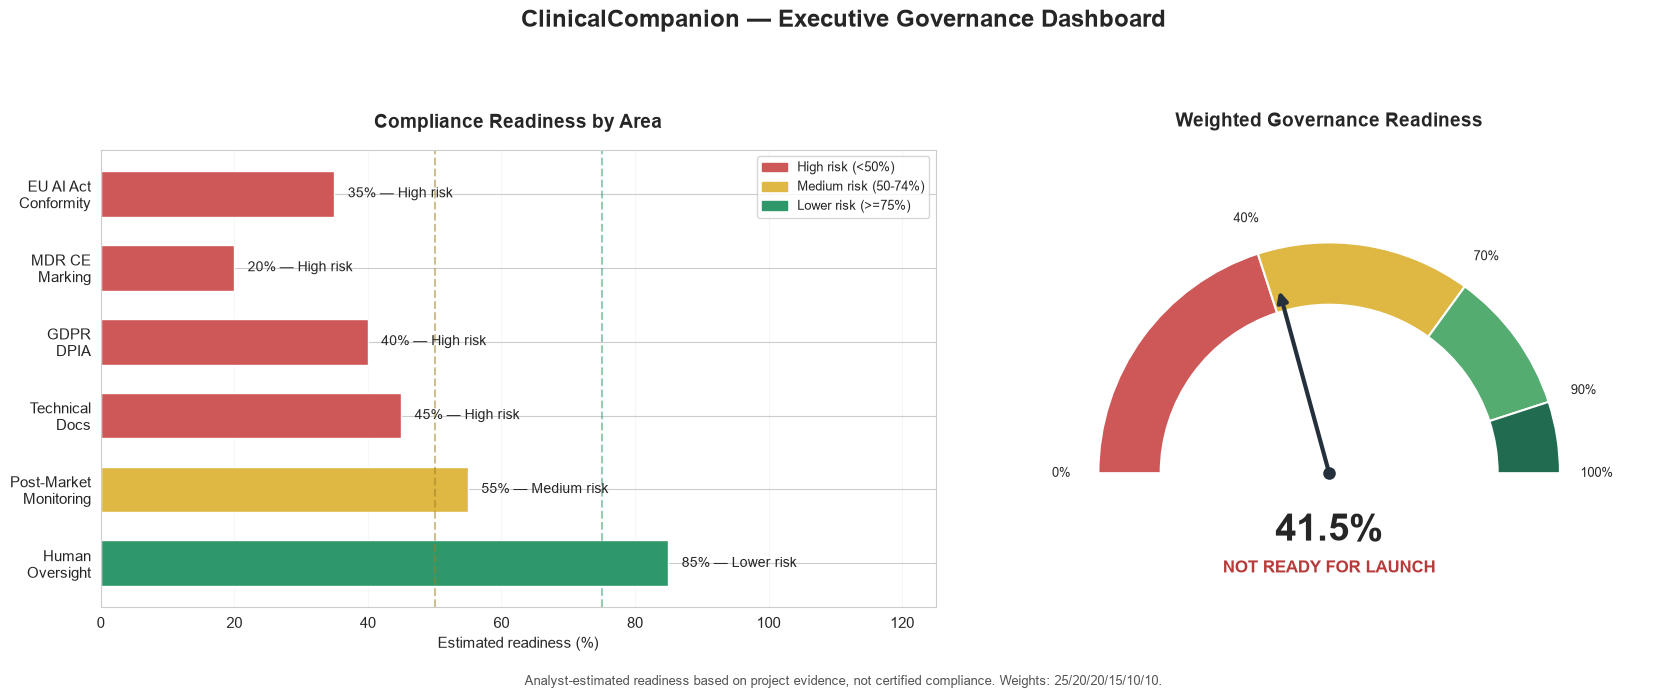

EXECUTIVE GOVERNANCE READINESS
EU AI Act Conformity: 35% (weight: 25%)
MDR CE Marking: 20% (weight: 20%)
GDPR DPIA: 40% (weight: 20%)
Technical Docs: 45% (weight: 15%)
Post-Market Monitoring: 55% (weight: 10%)
Human Oversight: 85% (weight: 10%)

Overall Weighted Readiness: 41.5%
Board Recommendation: NO-GO at present

Critical issues requiring remediation:
- Outstanding high-severity compliance gaps
- Medical device conformity assessment pending
- Hallucination rate above internal target
- Below-target subgroup performance
- GDPR DPIA and vendor governance gaps

Saved: results/executive_dashboard.png


In [19]:

# Step 8a: Executive Governance Readiness Dashboard

from matplotlib.patches import Wedge, Patch

# ==========================================
# PART 1: EVIDENCE-BASED READINESS ESTIMATES
# ==========================================

# Review the compliance findings
compliance_df = pd.read_csv(
    DATA_DIR / "eu_ai_act_requirements.csv"
)

open_gaps = (
    compliance_df["current_status"] != "Compliant"
).sum()

print(f"Outstanding EU AI Act gaps: {open_gaps}")

# Readiness estimates based on Steps 1-7
# These are analyst assessments, not certified results.

areas = [
    "EU AI Act\nConformity",
    "MDR CE\nMarking",
    "GDPR\nDPIA",
    "Technical\nDocs",
    "Post-Market\nMonitoring",
    "Human\nOversight"
]

readiness = np.array(
    [35, 20, 40, 45, 55, 85],
    dtype=float
)

# Assign importance weights
weights = np.array(
    [0.25, 0.20, 0.20, 0.15, 0.10, 0.10]
)

assert np.isclose(weights.sum(), 1.0)

# Calculate weighted governance readiness
score = np.average(
    readiness,
    weights=weights
)

# Determine qualitative risk ratings
def risk_level(pct):

    if pct >= 75:
        return "Lower risk", "#2e986b"

    elif pct >= 50:
        return "Medium risk", "#dfb743"

    else:
        return "High risk", "#ce5757"


ratings = [
    risk_level(value)
    for value in readiness
]

# ==========================================
# PART 2: CREATE DASHBOARD FIGURE
# ==========================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={
        "width_ratios": [1.2, 1]
    }
)

# ==========================================
# LEFT PANEL: COMPLIANCE READINESS BARS
# ==========================================

positions = np.arange(len(areas))

bars = ax1.barh(
    positions,
    readiness,
    color=[color for _, color in ratings],
    height=0.62
)

ax1.set_yticks(positions)
ax1.set_yticklabels(areas)
ax1.invert_yaxis()

# Add labels for each governance area
for bar, value, (rating, _) in zip(
    bars, readiness, ratings
):

    ax1.text(
        value + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.0f}% — {rating}",
        va="center",
        fontsize=10
    )

# Reference lines for readiness categories
ax1.axvline(
    50,
    color="#a18022",
    linestyle="--",
    alpha=0.5
)

ax1.axvline(
    75,
    color="#2e986b",
    linestyle="--",
    alpha=0.5
)

ax1.set_xlim(0, 125)
ax1.set_xlabel("Estimated readiness (%)")

ax1.set_title(
    "Compliance Readiness by Area",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax1.grid(axis="x", alpha=0.17)
ax1.set_axisbelow(True)

# Add the legend
ax1.legend(
    handles=[
        Patch(
            color="#ce5757",
            label="High risk (<50%)"
        ),
        Patch(
            color="#dfb743",
            label="Medium risk (50-74%)"
        ),
        Patch(
            color="#2e986b",
            label="Lower risk (>=75%)"
        )
    ],
    loc="upper right",
    fontsize=9
)

# ==========================================
# RIGHT PANEL: SEMICIRCULAR GAUGE
# ==========================================

# Gauge color bands
segments = [
    (0, 40, "#ce5757"),
    (40, 70, "#dfb743"),
    (70, 90, "#54ac70"),
    (90, 100, "#216b50")
]

# Draw each gauge segment
for low, high, color in segments:

    start_angle = 180 * (1 - high / 100)
    end_angle = 180 * (1 - low / 100)

    segment = Wedge(
        (0, 0),
        1.0,
        start_angle,
        end_angle,
        width=0.27,
        facecolor=color,
        edgecolor="white",
        linewidth=1.5
    )

    ax2.add_patch(segment)

# Calculate needle angle from readiness score
theta = np.pi * (1 - score / 100)

needle_x = 0.83 * np.cos(theta)
needle_y = 0.83 * np.sin(theta)

# Draw the needle
ax2.annotate(
    "",
    xy=(needle_x, needle_y),
    xytext=(0, 0),
    arrowprops={
        "arrowstyle": "-|>",
        "lw": 3,
        "color": "#24313d",
        "mutation_scale": 15
    }
)

# Draw needle pivot
ax2.scatter(
    [0],
    [0],
    s=65,
    color="#24313d",
    zorder=5
)

# Add percentage labels around the gauge
for value in [0, 40, 70, 90, 100]:

    angle = np.pi * (1 - value / 100)

    ax2.text(
        1.16 * np.cos(angle),
        1.16 * np.sin(angle),
        f"{value}%",
        ha="center",
        va="center",
        fontsize=9
    )

# Display weighted readiness score
ax2.text(
    0, -0.25,
    f"{score:.1f}%",
    ha="center",
    va="center",
    fontsize=27,
    fontweight="bold"
)

# Board-level status
ax2.text(
    0, -0.43,
    "NOT READY FOR LAUNCH",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#b83b3b"
)

ax2.set_xlim(-1.38, 1.38)
ax2.set_ylim(-0.58, 1.40)

ax2.set_aspect("equal")
ax2.axis("off")

ax2.set_title(
    "Weighted Governance Readiness",
    fontsize=14,
    fontweight="bold",
    pad=17
)

# ==========================================
# PART 3: SAVE AND DISPLAY
# ==========================================

fig.suptitle(
    "ClinicalCompanion — Executive Governance Dashboard",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5,
    0.025,
    "Analyst-estimated readiness based on project evidence, "
    "not certified compliance. "
    "Weights: 25/20/20/15/10/10.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(
    rect=(0, 0.05, 1, 0.92),
    w_pad=3
)

plt.savefig(
    RESULTS_DIR / "executive_dashboard.png",
    dpi=150,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ==========================================
# PART 4: EXECUTIVE SUMMARY OUTPUT
# ==========================================

print("=" * 70)
print("EXECUTIVE GOVERNANCE READINESS")
print("=" * 70)

for area, value, weight in zip(
    areas, readiness, weights
):
    name = area.replace("\n", " ")

    print(
        f"{name}: {value:.0f}% "
        f"(weight: {weight * 100:.0f}%)"
    )

print(f"\nOverall Weighted Readiness: {score:.1f}%")
print("Board Recommendation: NO-GO at present")

print("\nCritical issues requiring remediation:")
print("- Outstanding high-severity compliance gaps")
print("- Medical device conformity assessment pending")
print("- Hallucination rate above internal target")
print("- Below-target subgroup performance")
print("- GDPR DPIA and vendor governance gaps")

print("\nSaved: results/executive_dashboard.png")


---
## Deliverables Checklist

Before submitting, verify you have completed both deliverables:

### Notebook (this file)
- [ ] Step 1: System spec exploration — key facts extracted
- [ ] Step 2: EU AI Act classification — decision tree + gap analysis
- [ ] Step 3: Risk assessment — summary statistics + mitigation analysis
- [ ] Step 4: Risk heatmap + mitigation comparison — saved to `results/`
- [ ] Step 5: Vendor evaluation chart — saved to `results/`
- [ ] Step 6: Model card performance chart — saved to `results/`
- [ ] Step 7: Monitoring dashboard (4 panels) — saved to `results/`
- [ ] Step 8: Executive dashboard — saved to `results/`

### Workbook (`governance_workbook.xlsx`)
- [ ] Sheet 1: EU AI Act Classification — classification + compliance gap table
- [ ] Sheet 2: Risk Register — all 8 risks with scores and mitigations
- [ ] Sheet 3: Vendor Evaluation — category scores + recommendation
- [ ] Sheet 4: Model Card — full model card content
- [ ] Sheet 5: Monitoring & Incidents — KPI table + incident response plan
- [ ] Sheet 6: Executive Summary — board-ready narrative

### Results folder
Verify these 6 files exist in `results/`:
- [ ] `risk_heatmap.png`
- [ ] `risk_mitigation_comparison.png`
- [ ] `vendor_evaluation_chart.png`
- [ ] `model_card_performance.png`
- [ ] `monitoring_dashboard.png`
- [ ] `executive_dashboard.png`